# 02 · Wavelet coherence ที่เขียนเอง — และประตู G1

## สูตรที่ต้อง implement

$$R_n^2(s)=\frac{\left|S\!\left(s^{-1}W_n^{XY}(s)\right)\right|^2}
{S\!\left(s^{-1}\left|W_n^{X}(s)\right|^2\right)\cdot S\!\left(s^{-1}\left|W_n^{Y}(s)\right|^2\right)}$$

$$S(W)=S_{\text{scale}}\!\left(S_{\text{time}}(W)\right),\qquad
S_{\text{time}}(W)\big|_s=\left(W*c_1e^{-t^2/2s^2}\right)\Big|_s,\qquad
S_{\text{scale}}(W)\big|_n=\left(W*c_2\Pi(0.6s)\right)\Big|_n$$

## เกณฑ์ผ่านประตู G1

| # | เกณฑ์ | เกณฑ์เดิมในแผน |
| --- | --- | --- |
| ก | `wtc()` ของเรา เทียบ `pycwt.wct` | ต่างไม่เกิน **0.05** ในแถบ 2–7 ปี |
| ข | ทำซ้ำ premise test | อันดามันมีสัญญาณ ($p\approx0.016$) · อ่าวไทยไม่มี ($p\approx0.984$) |

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from wtc.transform import cwt, coi_mask, morlet_flambda, DJ, DT_MONTHLY, OMEGA0
from wtc.smoothing import (smooth, smooth_time, smooth_scale, boxcar_scale_weights,
                           gaussian_time_weights, DELTA_J0)
from wtc.coherence import wtc, xwt
from wtc.significance import fit_ar1, ar1_surrogate
from wtc.plotting import use_thai_font, plot_coherence, period_axis

FIGURES = ROOT / "figures"; FIGURES.mkdir(exist_ok=True)
use_thai_font()

d = np.load(ROOT / "data" / "processed" / "series.npz", allow_pickle=True)
t = d["t"]; Y, X = d["Y"], d["X"]
y_names = [str(s) for s in d["y_names"]]; x_names = [str(s) for s in d["x_names"]]
n, dt, dj = len(t), DT_MONTHLY, DJ
LABEL = {"ko_lak": "KO LAK (อ่าวไทย)", "ko_taphao_noi": "KO TAPHAO NOI (อันดามัน)",
         "fort_phrachula_chomklao": "FORT PHRACHULA"}
print(f"{n} เดือน · {t[0]:.3f}–{t[-1]:.3f} · dt={dt:.5f} ปี · dj={dj:.5f} · Morlet ω₀={OMEGA0:.0f}")

865 เดือน · 1951.042–2023.042 · dt=0.08333 ปี · dj=0.08333 · Morlet ω₀=6


## 1. ทำไม smoothing ถึงเป็นหัวใจ — ดูด้วยตาเลย

$$\frac{|W^{XY}|^2}{|W^X|^2|W^Y|^2}=\frac{|W^X|^2|W^Y|^2}{|W^X|^2|W^Y|^2}\equiv 1$$

In [2]:
y = Y[y_names.index("ko_taphao_noi")]
x = X[x_names.index("nino34")]
Wy, scales, periods, coi = cwt(y, dt, dj)
Wx, _, _, _ = cwt(x, dt, dj)

Wxy = xwt(Wy, Wx)
no_smooth = np.abs(Wxy) ** 2 / (np.abs(Wy) ** 2 * np.abs(Wx) ** 2)
R2, phase = wtc(Wy, Wx, dt, dj, scales)

print(f"ไม่ smooth : ค่าต่ำสุด {no_smooth.min():.12f} · สูงสุด {no_smooth.max():.12f} "
      f"⇒ เท่ากับ 1 ทุกจุด (ต่างจาก 1 ไม่เกิน {np.abs(no_smooth-1).max():.2e})")
print(f"smooth แล้ว: ค่าต่ำสุด {R2.min():.4f} · สูงสุด {R2.max():.4f} · เฉลี่ย {R2.mean():.4f}")
assert np.abs(no_smooth - 1).max() < 1e-9

ไม่ smooth : ค่าต่ำสุด 1.000000000000 · สูงสุด 1.000000000000 ⇒ เท่ากับ 1 ทุกจุด (ต่างจาก 1 ไม่เกิน 1.33e-15)
smooth แล้ว: ค่าต่ำสุด 0.0000 · สูงสุด 0.9537 · เฉลี่ย 0.3265


## 2. น้ำหนักของ smoothing operator

Font 'default' does not have a glyph for 'G' [U+47], substituting with a dummy symbol.


Font 'default' does not have a glyph for 'a' [U+61], substituting with a dummy symbol.


Font 'default' does not have a glyph for 'u' [U+75], substituting with a dummy symbol.


Font 'default' does not have a glyph for 's' [U+73], substituting with a dummy symbol.


Font 'default' does not have a glyph for 'i' [U+69], substituting with a dummy symbol.


...

Font 'default' does not have a glyph for '/' [U+2f], substituting with a dummy symbol.


Font 'default' does not have a glyph for 'd' [U+64], substituting with a dummy symbol.


Font 'default' does not have a glyph for 'j' [U+6a], substituting with a dummy symbol.


Font 'default' does not have a glyph for ')' [U+29], substituting with a dummy symbol.


Font 'default' does not have a glyph for '\xb7' [U+b7], substituting with a dummy symbol.


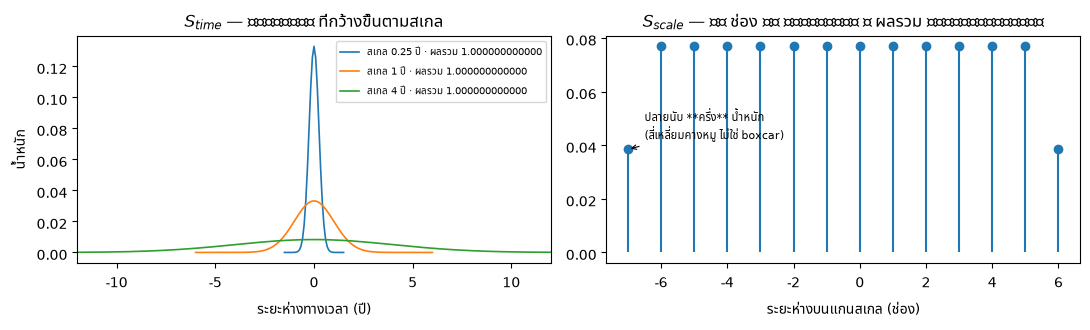

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for s, c in zip([0.25, 1.0, 4.0], ["C0", "C1", "C2"]):
    w = gaussian_time_weights(s, dt)
    lag = np.arange(-(len(w)//2), len(w)//2 + 1) * dt
    ax[0].plot(lag, w, color=c, lw=1.2, label=f"สเกล {s:g} ปี · ผลรวม {w.sum():.12f}")
ax[0].set_xlim(-12, 12); ax[0].set_xlabel("ระยะห่างทางเวลา (ปี)"); ax[0].set_ylabel("น้ำหนัก")
ax[0].set_title("$S_{time}$ — Gaussian ที่กว้างขึ้นตามสเกล"); ax[0].legend(fontsize=7)

w = boxcar_scale_weights(dj)
ax[1].stem(np.arange(len(w)) - len(w)//2, w, basefmt=" ")
ax[1].set_title(f"$S_{{scale}}$ — {len(w)} ช่อง (= 2×{DELTA_J0}/dj) · ผลรวม {w.sum():.12f}")
ax[1].set_xlabel("ระยะห่างบนแกนสเกล (ช่อง)")
ax[1].annotate("ปลายนับ **ครึ่ง** น้ำหนัก\n(สี่เหลี่ยมคางหมู ไม่ใช่ boxcar)",
               xy=(-len(w)//2, w[0]), xytext=(-6.5, w.max()*0.55), fontsize=8,
               arrowprops=dict(arrowstyle="->", lw=0.8))
fig.tight_layout(); fig.savefig(FIGURES / "w1-smoothing-kernels.png", dpi=130); plt.show()

## 3. สเปกตรัมกำลังและกรวยอิทธิพล (COI)

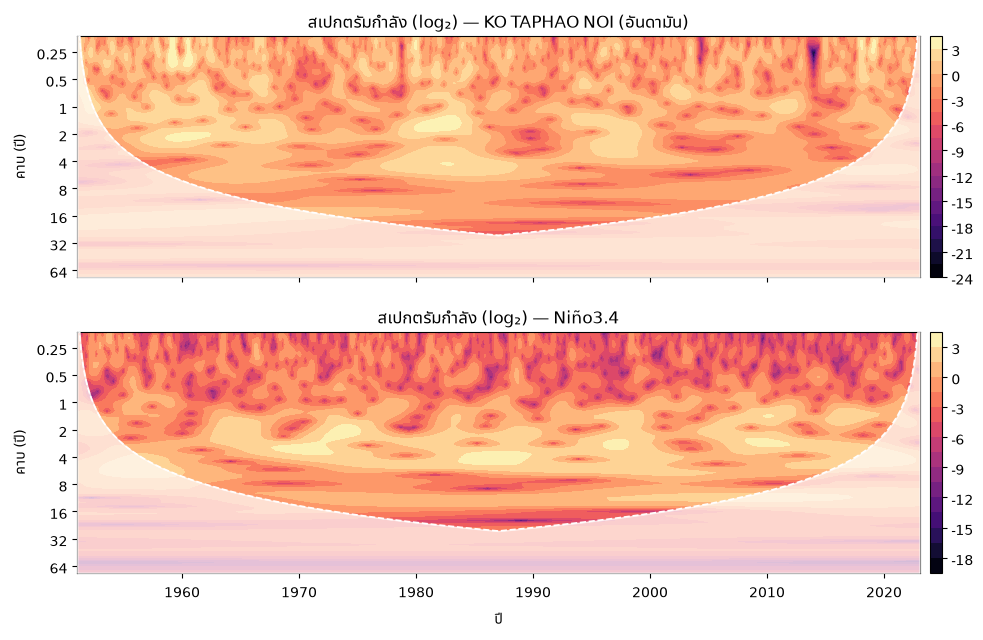

พื้นที่ในกรวย = 66.3% ของระนาบทั้งหมด


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for ax, (W, name) in zip(axes, [(Wy, LABEL["ko_taphao_noi"]), (Wx, "Niño3.4")]):
    power = np.abs(W) ** 2 / scales[:, None]
    m = ax.contourf(t, periods, np.log2(power + 1e-12), levels=18, cmap="magma")
    ax.fill_between(t, coi, periods.max(), color="white", alpha=0.7, zorder=3)
    ax.plot(t, coi, "w--", lw=1.2, zorder=4)
    period_axis(ax, periods)
    ax.set_title(f"สเปกตรัมกำลัง (log₂) — {name}")
    plt.colorbar(m, ax=ax, pad=0.01)
axes[-1].set_xlabel("ปี")
fig.tight_layout(); fig.savefig(FIGURES / "w1-power-spectra.png", dpi=130); plt.show()
print(f"พื้นที่ในกรวย = {coi_mask(periods, coi).mean():.1%} ของระนาบทั้งหมด")

## 4. Wavelet coherence — ผลจากโค้ดของเรา

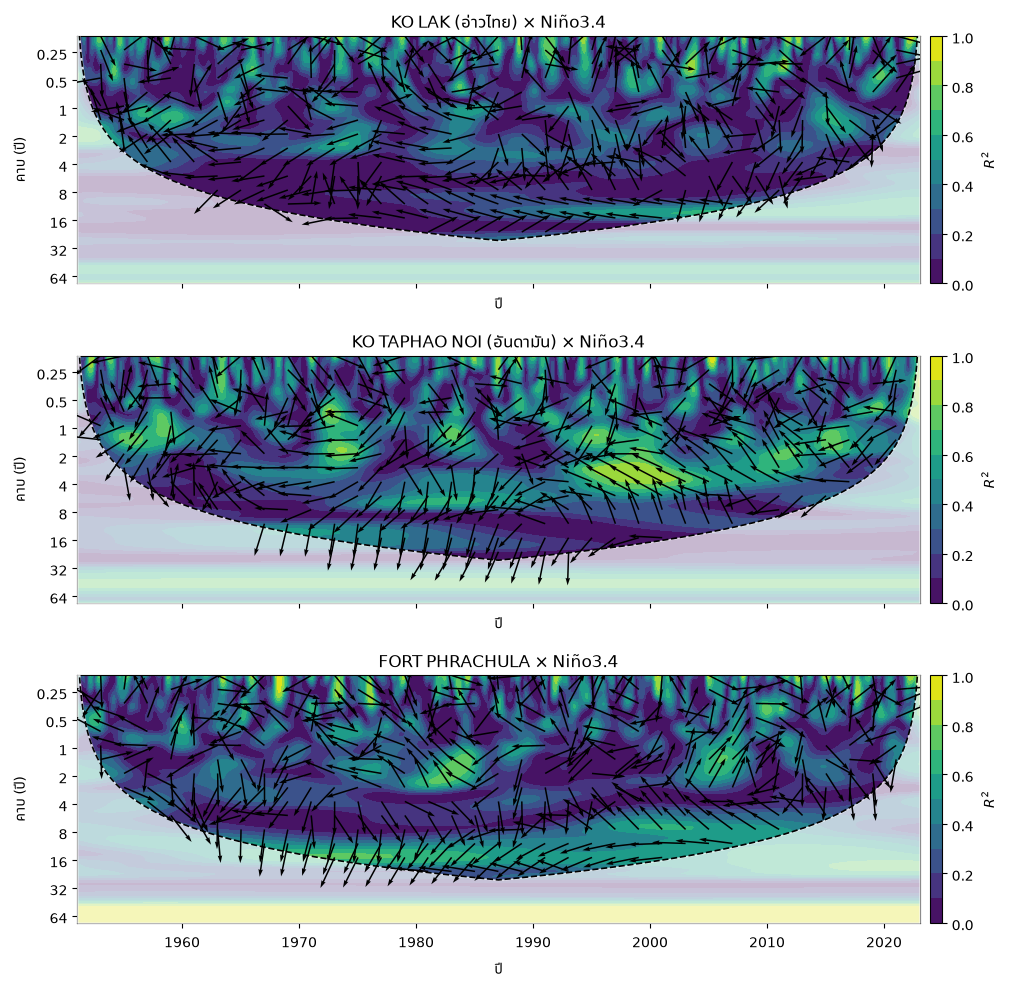

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, key in zip(axes, y_names):
    Wk, sc_k, per_k, coi_k = cwt(Y[y_names.index(key)], dt, dj)
    R2k, phk = wtc(Wk, Wx, dt, dj, sc_k)
    cf = plot_coherence(ax, t, per_k, R2k, coi_k, phase=phk, title=f"{LABEL[key]} × Niño3.4")
    plt.colorbar(cf, ax=ax, pad=0.01, label="$R^2$")
fig.tight_layout(); fig.savefig(FIGURES / "w1-wtc-nino34.png", dpi=130); plt.show()

## 5. 🚦 ประตู G1 (ก) — เทียบกับ `pycwt.wct`

In [6]:
import pycwt

s0 = 2 * dt / morlet_flambda(OMEGA0)
J = int(round(np.log2(n * dt / s0) / dj))
band = (periods >= 2) & (periods <= 7)
inside = coi_mask(periods, coi)

print(f"  {'สถานี':28s} {'แถบ 2–7 ปี':>14s} {'ทั้งระนาบในกรวย':>18s}")
worst = {}
for key in y_names:
    yk = Y[y_names.index(key)]
    Wk, sc_k, _, _ = cwt(yk, dt, dj)
    ours, _ = wtc(Wk, Wx, dt, dj, sc_k)
    theirs, _, coi_l, freq_l, _ = pycwt.wct(yk, x, dt, dj=dj, s0=s0, J=J, sig=False,
                                            wavelet=pycwt.Morlet(OMEGA0), normalize=False)
    assert np.allclose(1/freq_l, periods) and np.allclose(coi_l, coi)
    diff = np.abs(ours - theirs)
    worst[key] = diff[band][inside[band]].max()
    print(f"  {LABEL[key]:28s} {worst[key]:14.3e} {diff[inside].max():18.3e}")

print(f"\nเกณฑ์คือ ≤ 0.05 — ได้จริง {max(worst.values()):.3e} "
      f"คือดีกว่าเกณฑ์ประมาณ {0.05/max(worst.values()):.0e} เท่า")
assert max(worst.values()) < 1e-10, "ไม่ใช่แค่ใกล้เคียง — ต้องตรงกันระดับ floating point"
print("✅ ประตู G1 (ก) ผ่าน — ไม่ใช่ 'ใกล้เคียงพอ' แต่เป็นสูตรเดียวกันจริง")

  สถานี                            แถบ 2–7 ปี    ทั้งระนาบในกรวย
  KO LAK (อ่าวไทย)                  8.882e-16          1.388e-15
  KO TAPHAO NOI (อันดามัน)          1.332e-15          1.005e-14
  FORT PHRACHULA                    8.882e-16          5.107e-15

เกณฑ์คือ ≤ 0.05 — ได้จริง 1.332e-15 คือดีกว่าเกณฑ์ประมาณ 4e+13 เท่า
✅ ประตู G1 (ก) ผ่าน — ไม่ใช่ 'ใกล้เคียงพอ' แต่เป็นสูตรเดียวกันจริง


### ระหว่างทางเจออะไรบ้าง — สามจุดที่ต้องรู้

In [7]:
def smooth_flat_box(W, dt_, dj_, sc_):
    w = np.ones(int(round(2 * DELTA_J0 / dj_))); w /= w.sum()
    T = smooth_time(W, dt_, sc_)
    num = np.apply_along_axis(lambda c: np.convolve(c, w, "same"), 0, T)
    den = np.apply_along_axis(lambda c: np.convolve(c, w, "same"), 0, np.ones((W.shape[0], 1)))
    return num / den

Sxy = smooth_flat_box(xwt(Wy, Wx) / scales[:, None], dt, dj, scales)
Sxx = smooth_flat_box(np.abs(Wy)**2 / scales[:, None], dt, dj, scales)
Syy = smooth_flat_box(np.abs(Wx)**2 / scales[:, None], dt, dj, scales)
wrong = np.abs(Sxy)**2 / (Sxx * Syy)
diff = np.abs(wrong - R2)
print(f"(1) boxcar แบนแทนสี่เหลี่ยมคางหมู -> ต่างสูงสุด {diff[inside].max():.4f} "
      f"เฉลี่ย {diff[inside].mean():.4f}")

(1) boxcar แบนแทนสี่เหลี่ยมคางหมู -> ต่างสูงสุด 0.0769 เฉลี่ย 0.0148


In [8]:
from scipy.fft import next_fast_len
print(f"    n = {n} · กำลังสองถัดไป = {int(2**np.ceil(np.log2(n)))} · next_fast_len = {next_fast_len(n)}")

def smooth_time_padded(W, m):
    k = 2 * np.pi * np.fft.fftfreq(m)
    sig = (scales / dt)[:, None]
    return np.fft.ifft(np.exp(-0.5 * sig**2 * k[None, :]**2) * np.fft.fft(W, m, axis=1), axis=1)[:, :n]

def wtc_with_pad(m):
    S = lambda A: smooth_scale(smooth_time_padded(A, m), dj)
    a = S(xwt(Wy, Wx) / scales[:, None]); b = S(np.abs(Wy)**2 / scales[:, None]); c = S(np.abs(Wx)**2 / scales[:, None])
    return np.abs(a)**2 / np.abs(b * c)

diff2 = np.abs(wtc_with_pad(next_fast_len(n)) - R2)
print(f"(2) เติมถึง 875 แทน 1024 -> ต่างสูงสุด {diff2[inside].max():.4f} "
      f"เฉลี่ย {diff2[inside].mean():.5f}  (กองอยู่ที่ขอบ)")

    n = 865 · กำลังสองถัดไป = 1024 · next_fast_len = 875
(2) เติมถึง 875 แทน 1024 -> ต่างสูงสุด 0.0535 เฉลี่ย 0.00121  (กองอยู่ที่ขอบ)


In [9]:
A = np.abs(Wy)**2 / scales[:, None]
ratio = smooth_scale(smooth_time(A, dt, scales), dj, edge="renorm") / \
        smooth_scale(smooth_time(A, dt, scales), dj, edge="zero")
print(f"(3) อัตราส่วน renorm/zero ต่างกันตามคอลัมน์เวลาไหม: "
      f"{'ไม่ต่างเลย' if np.allclose(ratio, ratio[:, :1]) else 'ต่าง'}")
print(f"    แถวบนสุดถูกคูณด้วย {ratio[0,0]:.3f} · แถวล่างสุด {ratio[-1,0]:.3f} · แถวกลาง {ratio[len(ratio)//2,0]:.3f}")
R2_zero, _ = wtc(Wy, Wx, dt, dj, scales, compat=True)
print(f"    ยืนยัน: R² ของสองแบบต่างกันสูงสุด {np.abs(R2_zero - R2).max():.2e}")

(3) อัตราส่วน renorm/zero ต่างกันตามคอลัมน์เวลาไหม: ไม่ต่างเลย
    แถวบนสุดถูกคูณด้วย 2.000 · แถวล่างสุด 1.733 · แถวกลาง 1.000
    ยืนยัน: R² ของสองแบบต่างกันสูงสุด 7.77e-16


## 6. 🚦 ประตู G1 (ข) — ทำซ้ำ premise test ด้วยโค้ดเราล้วน

$$p=\frac{\#\{\text{null}\ge\text{obs}\}+1}{N_{MC}+1}$$

In [10]:
BAND = (2.0, 7.0)

def band_mean(R2_, per_, coi_):
    sel = (per_ >= BAND[0]) & (per_ <= BAND[1])
    ins = coi_mask(per_, coi_)
    return float(np.nanmean(R2_[sel][ins[sel]]))

NMC, SEED = 60, 7
rng = np.random.default_rng(SEED)
ax_, sx_ = fit_ar1(x)
results = {}
for key in ("ko_taphao_noi", "ko_lak"):
    yk = Y[y_names.index(key)]
    Wk, sc_k, per_k, coi_k = cwt(yk, dt, dj)
    obs = band_mean(wtc(Wk, Wx, dt, dj, sc_k)[0], per_k, coi_k)
    ay, sy = fit_ar1(yk)
    null = np.empty(NMC)
    for i in range(NMC):
        Wa, sa, pa, ca = cwt(ar1_surrogate(n, ay, sy, rng), dt, dj)
        Wb, _, _, _ = cwt(ar1_surrogate(n, ax_, sx_, rng), dt, dj)
        null[i] = band_mean(wtc(Wa, Wb, dt, dj, sa)[0], pa, ca)
    p = (np.sum(null >= obs) + 1) / (NMC + 1)
    results[key] = (obs, null, p, ay)
    print(f"  {LABEL[key]:28s} AR(1) a={ay:.3f} · coherence = {obs:.4f} · "
          f"null p95 = {np.percentile(null,95):.4f} ⇒ p = {p:.3f} "
          f"{'✅ มีนัยสำคัญ' if p < 0.05 else '❌ ไม่ผ่าน'}")
print(f"  Niño3.4: AR(1) a = {ax_:.3f}")

  KO TAPHAO NOI (อันดามัน)     AR(1) a=0.707 · coherence = 0.3489 · null p95 = 0.2970 ⇒ p = 0.016 ✅ มีนัยสำคัญ


  KO LAK (อ่าวไทย)             AR(1) a=0.504 · coherence = 0.1654 · null p95 = 0.3177 ⇒ p = 0.984 ❌ ไม่ผ่าน
  Niño3.4: AR(1) a = 0.943


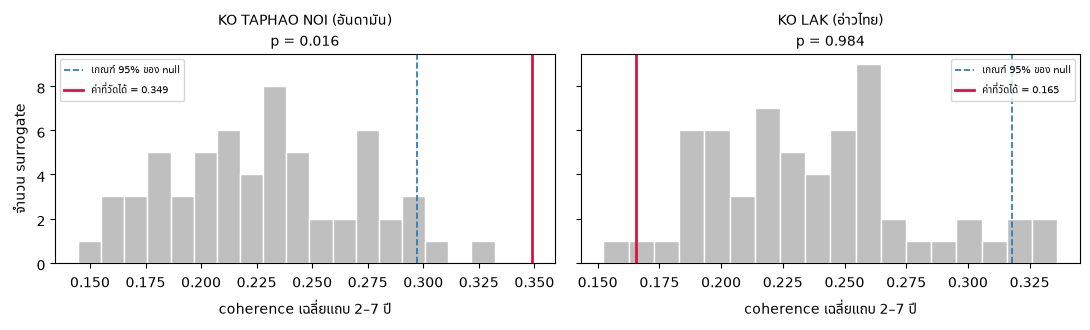

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, key in zip(axes, ("ko_taphao_noi", "ko_lak")):
    obs, null, p, _ = results[key]
    ax.hist(null, bins=18, color="0.75", edgecolor="w")
    ax.axvline(np.percentile(null, 95), color="C0", ls="--", lw=1.2, label="เกณฑ์ 95% ของ null")
    ax.axvline(obs, color="crimson", lw=2, label=f"ค่าที่วัดได้ = {obs:.3f}")
    ax.set_title(f"{LABEL[key]}\np = {p:.3f}", fontsize=10)
    ax.set_xlabel("coherence เฉลี่ยแถบ 2–7 ปี"); ax.legend(fontsize=7)
axes[0].set_ylabel("จำนวน surrogate")
fig.tight_layout(); fig.savefig(FIGURES / "w1-premise-test.png", dpi=130); plt.show()

## 7. สรุปประตู G1

In [12]:
gate_a = max(worst.values()) <= 0.05
gate_b = results["ko_taphao_noi"][2] < 0.05 <= results["ko_lak"][2]
print(f"  (ก) ต่างจาก pycwt.wct สูงสุดในแถบ 2–7 ปี = {max(worst.values()):.3e}  (เกณฑ์ ≤ 0.05)  "
      f"{'✅' if gate_a else '❌'}")
print(f"  (ข) อันดามัน p = {results['ko_taphao_noi'][2]:.3f} · อ่าวไทย p = {results['ko_lak'][2]:.3f}  "
      f"{'✅' if gate_b else '❌'}")
assert gate_a and gate_b
print("\n  🚦 ประตู G1 ผ่านทั้งสองข้อ — เดินต่อตามแผนได้")

  (ก) ต่างจาก pycwt.wct สูงสุดในแถบ 2–7 ปี = 1.332e-15  (เกณฑ์ ≤ 0.05)  ✅
  (ข) อันดามัน p = 0.016 · อ่าวไทย p = 0.984  ✅

  🚦 ประตู G1 ผ่านทั้งสองข้อ — เดินต่อตามแผนได้


## สรุปของโน้ตบุ๊กนี้

### สิ่งที่ยังไม่มีในโน้ตบุ๊กนี้ (และอยู่สัปดาห์ไหน)

| ขาด | ผลที่ตามมา | กำหนด |
| --- | --- | --- |
| เส้นชั้นนัยสำคัญบนรูป coherence | สีเข้มยังตีความว่า "มีสัญญาณ" ไม่ได้ | W4 `significance.threshold_wtc` |
| PASC / AWC | ยังเทียบกับเลขของเปเปอร์ต้นทางไม่ได้ | W4 `metrics.py` |
| MWC | ยังตอบ Q3–Q5 ไม่ได้ | W5 `coherence.mwc` |
| โซ่ anti-alias + decimation | ยังตอบ Q7 ไม่ได้ | W2 `multirate.py` |